# Ablation analysis of nearest neighbor algorithm

Effects of changing the nearest-neighbor graph construction algorithm.

In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
ordered_metrics = [
    'MCC', 'F1', 'JACC', 'PURITY', 'HOMO', 'CCENT', # Cluster-as-prediction
    'COMP', # Joint bio&batch
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'BATCHARI', 'BCENT', 'BP', 'CRE'
]

batch_metrics = ['BATCHARI', 'BCENT', 'BP', 'CRE']

In [4]:
def test_k1_k2(df_metric, k1, k2):
    k15 = df_metric[df_metric['neighbor_type'] == k1].set_index('Integration')['Value']
    k20 = df_metric[df_metric['neighbor_type'] == k2].set_index('Integration')['Value']
    
    # Align on Integration
    common = k15.index.intersection(k20.index)
    k15 = k15.loc[common]
    k20 = k20.loc[common]
    
    if len(common) < 3:
        return pd.Series({'statistic': np.nan, 'p_value': np.nan, 'direction': np.nan})
    
    diff = k20 - k15
    mean_diff = diff.mean()

    # Wilcoxon signed-rank test (non-parametric, no normality assumption)
    stat, p = wilcoxon(k15, k20, alternative='two-sided')
    
    return pd.Series({
        'statistic': stat,
        'p_value': p,
        'mean_diff': mean_diff,  # positive = increases from k15 to k20
        'direction': 'increase' if mean_diff > 0 else 'decrease'
    })

In [5]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='neighbor_type', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

## Collect the data from the eight different datasets

The combined metric file is available as `robustness_neighbor_algorithm_louvain.csv`. To reproduce the Kendall's W, instead of using the code to load the CSV files, instead subset the metric file to the given dataset. e.g.

```Python
df_full = pd.read_csv('../data/source_data/robustness_neighbor_algorithm_louvain.csv')
df_sub = df_full[df_full['Dataset'] == 'neurips_bmmc']
```

### Neurips BMMC

In [6]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_neurips_bmmc/metrics/all-metrics.csv')

df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [7]:
w_results_1 = compute_w_across_integrations(df_sub)
w_results_1['Dataset'] = "neurips_bmmc"
w_results_1

,Metric,Kendall_W,Dataset
0,AMI,0.964346,neurips_bmmc
1,ARI,0.905366,neurips_bmmc
2,AWC,0.910173,neurips_bmmc
3,BAMI,0.948923,neurips_bmmc
4,BARI,0.950674,neurips_bmmc
5,BATCHARI,0.917404,neurips_bmmc
6,BCENT,0.851496,neurips_bmmc
7,BP,0.873940,neurips_bmmc
8,BVM,0.948462,neurips_bmmc
9,CCENT,0.979479,neurips_bmmc


In [8]:
df_1 = df_sub.copy()

### scIB sim1

In [9]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3])
df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)

plt.show()

In [10]:
w_results_2 = compute_w_across_integrations(df_sub)
w_results_2['Dataset'] = "scib_sim1"
w_results_2

,Metric,Kendall_W,Dataset
0,AMI,0.983433,scib_sim1
1,ARI,0.973343,scib_sim1
2,AWC,0.973611,scib_sim1
3,BAMI,0.991915,scib_sim1
4,BARI,0.990678,scib_sim1
5,BATCHARI,0.954986,scib_sim1
6,BCENT,0.968405,scib_sim1
7,BP,0.961260,scib_sim1
8,BVM,0.991915,scib_sim1
9,CCENT,0.985659,scib_sim1


In [11]:
df_2 = df_sub.copy()

### Mouse Mammary

In [12]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3])

df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [13]:
w_results_3 = compute_w_across_integrations(df_sub)
w_results_3['Dataset'] = "mouse_mammary"
w_results_3

,Metric,Kendall_W,Dataset
0,AMI,0.956223,mouse_mammary
1,ARI,0.945890,mouse_mammary
2,AWC,0.946484,mouse_mammary
3,BAMI,0.947250,mouse_mammary
4,BARI,0.939216,mouse_mammary
5,BATCHARI,0.978050,mouse_mammary
6,BCENT,0.928563,mouse_mammary
7,BP,0.953222,mouse_mammary
8,BVM,0.947250,mouse_mammary
9,CCENT,0.962922,mouse_mammary


In [14]:
df_3 = df_sub.copy()

### Human Pancreas

In [15]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas_rescue2/metrics/all-metrics.csv')
df = pd.concat([df, df2, df3])

# df = pd.concat([df, df2, df3])
df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [16]:
w_results_4 = compute_w_across_integrations(df_sub)
w_results_4['Dataset'] = "human_pancreas"
w_results_4

,Metric,Kendall_W,Dataset
0,AMI,0.993365,human_pancreas
1,ARI,0.989946,human_pancreas
2,AWC,0.991442,human_pancreas
3,BAMI,0.982321,human_pancreas
4,BARI,0.982715,human_pancreas
5,BATCHARI,0.973257,human_pancreas
6,BCENT,0.972728,human_pancreas
7,BP,0.968317,human_pancreas
8,BVM,0.982445,human_pancreas
9,CCENT,0.985200,human_pancreas


In [17]:
df_4 = df_sub.copy()

### Human pbmc seq techs

In [18]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs_rescue/metrics/all-metrics.csv')

df = pd.concat([df, df2])

df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [19]:
w_results_5 = compute_w_across_integrations(df_sub)
w_results_5['Dataset'] = "human_pbmc_seq_techs"
w_results_5

,Metric,Kendall_W,Dataset
0,AMI,0.990962,human_pbmc_seq_techs
1,ARI,0.984399,human_pbmc_seq_techs
2,AWC,0.986072,human_pbmc_seq_techs
3,BAMI,0.991544,human_pbmc_seq_techs
4,BARI,0.987640,human_pbmc_seq_techs
5,BATCHARI,0.940312,human_pbmc_seq_techs
6,BCENT,0.954540,human_pbmc_seq_techs
7,BP,0.950835,human_pbmc_seq_techs
8,BVM,0.991673,human_pbmc_seq_techs
9,CCENT,0.989632,human_pbmc_seq_techs


In [20]:
df_5 = df_sub.copy()

### Seurat PBMC

In [21]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_seurat_pbmc/metrics/all-metrics.csv')

df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [22]:
w_results_6 = compute_w_across_integrations(df_sub)
w_results_6['Dataset'] = "seurat_pbmc"
w_results_6

,Metric,Kendall_W,Dataset
0,AMI,0.973697,seurat_pbmc
1,ARI,0.952176,seurat_pbmc
2,AWC,0.962844,seurat_pbmc
3,BAMI,0.955469,seurat_pbmc
4,BARI,0.945617,seurat_pbmc
5,BATCHARI,0.927809,seurat_pbmc
6,BCENT,0.907618,seurat_pbmc
7,BP,0.921527,seurat_pbmc
8,BVM,0.955469,seurat_pbmc
9,CCENT,0.966427,seurat_pbmc


In [23]:
df_6 = df_sub.copy()

### Cellranger versions

In [24]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions_rescue2/metrics/all-metrics.csv')

df = pd.concat([df, df2, df3])
df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

In [ ]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [25]:
w_results_7 = compute_w_across_integrations(df_sub)
w_results_7['Dataset'] = "cellranger_versions"
w_results_7

,Metric,Kendall_W,Dataset
0,AMI,0.959925,cellranger_versions
1,ARI,0.950003,cellranger_versions
2,AWC,0.940154,cellranger_versions
3,BAMI,0.976765,cellranger_versions
4,BARI,0.971253,cellranger_versions
5,BATCHARI,0.942882,cellranger_versions
6,BCENT,0.961815,cellranger_versions
7,BP,0.957850,cellranger_versions
8,BVM,0.977543,cellranger_versions
9,CCENT,0.974317,cellranger_versions


In [26]:
df_7 = df_sub.copy()

### NPH Cerebellum

In [27]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_nph_cerebellum/metrics/all-metrics.csv')

df['Integration'] = df['Integration'].str[:-2]
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df.Metric != 'CLUSTACC']
df_sub = df[df['neighbor_k'] == 15]

/tmp/ipykernel_2032151/4055433094.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
/tmp/ipykernel_2032151/4055433094.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')
/tmp/ipykernel_2032151/4055433094.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value in

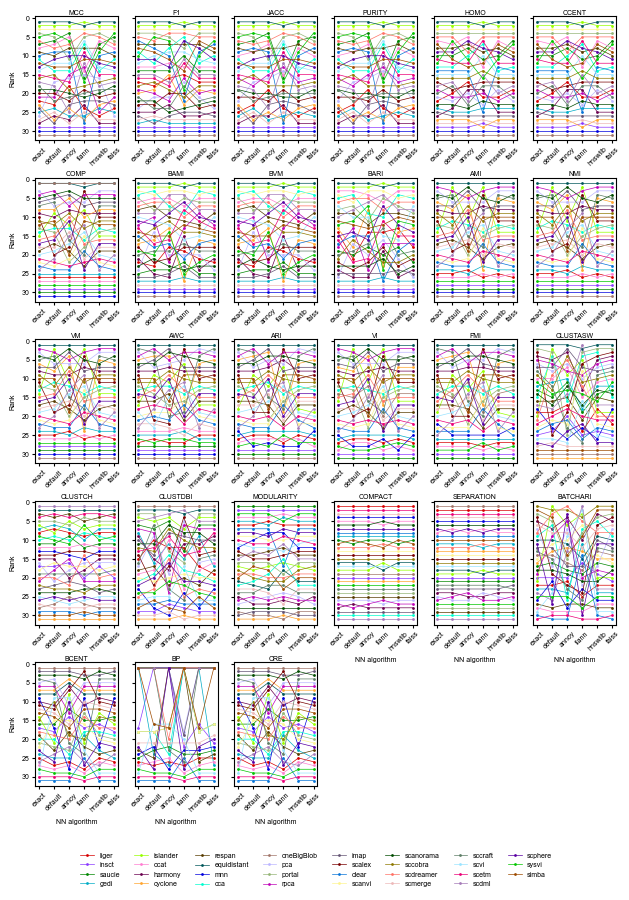

In [29]:
label_order = ['exact', 'default', 'annoy', 'flann', 'hnswlib', 'faiss']
df_sub['neighbor_type'] = pd.Categorical(df_sub['neighbor_type'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.5
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]

    sns.lineplot(
        data=subset, 
        x='neighbor_type', 
        y='Rank', 
        hue='Integration', 
        marker='o', 
        markersize=2,
        markeredgewidth=0,
        linewidth=0.5,
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=1)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=2
    )
    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('NN algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()
    ax.tick_params(axis='x', labelrotation=45)


for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.05),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)
axes[0].invert_yaxis()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [28]:
w_results_8 = compute_w_across_integrations(df_sub)
w_results_8['Dataset'] = "nph_cerebellum"
w_results_8

,Metric,Kendall_W,Dataset
0,AMI,0.903651,nph_cerebellum
1,ARI,0.906160,nph_cerebellum
2,AWC,0.903047,nph_cerebellum
3,BAMI,0.949440,nph_cerebellum
4,BARI,0.927935,nph_cerebellum
5,BATCHARI,0.698365,nph_cerebellum
6,BCENT,0.854906,nph_cerebellum
7,BP,0.798895,nph_cerebellum
8,BVM,0.949440,nph_cerebellum
9,CCENT,0.964404,nph_cerebellum


In [29]:
df_8 = df_sub.copy()

## Plot Kendall's W

In [30]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results.reset_index(drop=True, inplace=True)

In [31]:
control = pd.read_csv('../results/spreadsheets/louvain_seed_W.csv', index_col=0)

In [32]:
merged = w_results.merge(control, on=['Metric', 'Dataset'], how='left', suffixes=('_data', '_control'))
merged['diff_W'] = merged['Kendall_W_data'] - merged['Kendall_W_control']
merged['prop_W'] = merged['Kendall_W_data'] / merged['Kendall_W_control']

/tmp/ipykernel_2034908/166019800.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


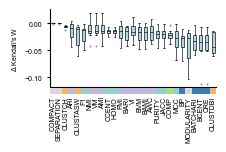

In [33]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

order = merged.groupby("Metric")["diff_W"].median().sort_values(ascending=False).index
h0 = 'Clusters-as-predictions & KNN'
h1 = 'Logistic regression'
h2 = 'Cluster-label similarity'
h3 = 'Isolated labels & GC'
h4 = 'Cell types as clusters'
h5 = 'Joint bioconservation & batch correction'
h6 = 'Cluster quality 1'
h7 = 'Fine-grained biology'
h8 = 'Cluster quality 2'
k0 = 'Primarily bioconservation'
k1 = 'BASW & SV'
k2 = 'Clustering metrics'
k3 = 'PCR & PROBELR'
k5 = 'Unique metrics'
k6 = 'KNN'
metric_to_group = {
    'fmi': h2, 'awc': h2, 'ari': h2, 'vi': h2, 'nmi': h2, 'ami': h2, 'vm':h2, 
    'bari': h2, 'bami': h2, 'bvm': h2, 
    'isoasw': h3, 'gc': h3, 'isof1': h3, 'isolisi': h3,
    'casw': h4, 'cdbi': h4, 'cch': h4, 
    'blogreg': h1, 'flogreg': h1, 
    'clisi': h0, 'fknn': h0, 'ksim': h0, 'ocs': h0, 'nnmap': h0, 'cnent': h0, 
    'cnentropyw': h0, 'bknn': h0, 'f1': h0, 'mcc': h0, 'jacc': h0, 'purity': h0, 
    'ccent': h0, 'homo': h0, 'arif': h0, 'nmif': h0, 
    'clustch': h6, 'clustasw': h6, 'clustdbi': h6, 
    'comp': h5, 'pptpc': h5, 'pstdb': h5, 
    'ldfdiff': h7, 'agree': h7, 'morani': h7, 'rknn': h7, 'ccc': h7, 
    'scgraph': h7, 'corrmse': h7, 'traj': h7, 'scgraphp': h7, 'scgraphm': h7,
    'modularity': h8, 'compact': h8, 'separation': h8,
    'mix': k6, 'align': k6, 'ilisi': k6, 'bnent': k6, 'kldiv': k6,
    'adgbd': k6, 'kbetall': k6, 'cilisi': k6, 'csms': k6, 'kbet': k6,
    'bras': k5, 'embdiv': k5, 'probe': k5,  'pcr': k3,
    'probelr': k3, 'proberf': k5,
    'bp': k2, 'bcent': k2, 'cre': k2, 'batchari': k2,
    'basw': k1, 'sv': k1,
}
group_to_color = {
    h0: '#8dd3c7', h1: '#ffffb3', h2: '#bebada', h3: '#fb8072', h4: '#80b1d3',
    h6: '#fdb462', h5: '#b3de69', h7: '#fccde5', h8: '#d9d9d9',
    k6: '#e41a1c', k5: '#4daf4a', k3: '#ff7f00', k2: '#377eb8', k1: 'ffff33', k0: '#a65628'
}

boxplot_data = [merged[merged["Metric"] == metric]["diff_W"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.1))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.tick_params(axis='x', length=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("$\\Delta$ Kendall's W", fontsize=5)
# ax.set_xlabel("Metric", fontsize=5)
# ax.set_title("Distribution of Kendall's W across Datasets by Metric")
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()  # finalize layout before adding patches

# --- sizing in points ---
box_h_pt   = 4    # height of each color box
box_w_pt   = 18   # width of each color box (adjust to taste)
gap_pt     = 0.6    # gap between tick line and box top

# Convert points to display units
dpi        = fig.dpi
pt_to_disp = dpi / 72.0

# Transform: x in data coords, y pinned to axes bottom in display coords
trans = ax.transData

if len(order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1  # 85% of spacing, leaving a small gap between boxes

for i, metric in enumerate(order):
    tick_x = i + 1
    grp    = metric_to_group.get(metric.lower(), "Unknown")
    color  = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    inv = ax.transAxes.inverted()
    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=5,
        rotation=90,
        clip_on=False,
    )
plt.savefig('../publication_figures/clustering_louvain_neighbor_algorithm_W.svg', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
merged.groupby("Metric")["diff_W"].mean().sort_values()

Metric
MODULARITY   -0.043070
CRE          -0.041040
BCENT        -0.041015
CLUSTDBI     -0.038233
BP           -0.034764
BATCHARI     -0.032919
MCC          -0.031016
CLUSTASW     -0.022465
PURITY       -0.021844
JACC         -0.021844
COMP         -0.021616
F1           -0.020269
BARI         -0.019866
BAMI         -0.019724
BVM          -0.019657
FMI          -0.017719
AWC          -0.016696
HOMO         -0.015309
CCENT        -0.015253
VI           -0.014310
ARI          -0.014245
AMI          -0.011911
NMI          -0.011901
VM           -0.011901
CLUSTCH      -0.006281
SEPARATION   -0.000345
COMPACT      -0.000203
Name: diff_W, dtype: float64

In [35]:
merged.groupby("Metric")["prop_W"].mean().sort_values()

Metric
MODULARITY    0.956721
CRE           0.957218
BCENT         0.957243
CLUSTDBI      0.960846
BP            0.963044
BATCHARI      0.964100
MCC           0.968242
CLUSTASW      0.976158
PURITY        0.977634
JACC          0.977634
COMP          0.977903
F1            0.979254
BARI          0.979674
BAMI          0.980047
BVM           0.980117
FMI           0.981534
AWC           0.982598
HOMO          0.984540
CCENT         0.984602
VI            0.985222
ARI           0.985236
AMI           0.987754
NMI           0.987763
VM            0.987763
CLUSTCH       0.993696
SEPARATION    0.999655
COMPACT       0.999796
Name: prop_W, dtype: float64

In [36]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('BARI', 'ARI'),
    ('BAMI', 'AMI'),
    ('BVM', 'VM')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(110.0), pvalue=np.float64(0.2530494780425657))

In [37]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('AMI', 'ARI'),
    ('BAMI', 'BARI')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(50.0), pvalue=np.float64(0.375457763671875))

## Differences in coefficient of variation

In [31]:
df_full = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
df_full = df_full[df_full.Metric != 'ISOF1']
df_full.replace([np.inf, -np.inf], np.nan, inplace=True)

In [33]:
df_full.to_csv('../results/spreadsheets/ablation_analysis_neighbor_algorithm_louvain.csv', index=False)

In [39]:
cvs = df_full.pivot(index=['Dataset', 'Integration', 'neighbor_type'],
                    columns='Metric', values="Value").groupby(['Dataset', 'neighbor_type'])[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()

In [40]:
def plot_cv_metrics(
    df: pd.DataFrame,
    dataset_col: str = "Dataset",
    k_col: str = "neighbor_type",
    reference_k = 'default',
    ncols: int = 6,
    figsize_per_cell: tuple = (1.1, 1),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple line charts of coefficient of variation (CV) vs neighbor_k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a reference k value.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain `dataset_col`, `k_col`, and one column per metric.
    dataset_col : str
        Column name identifying datasets.
    k_col : str
        Column name for neighbor_k values.
    reference_k : int
        The k value to test significance against (default 15).
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    """
    import matplotlib.ticker as mticker
    from scipy.stats import wilcoxon
    metric_cols = ordered_metrics
    k_values = sorted(df[k_col].unique())
    n_metrics = len(metric_cols)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    ref_data = {}
    for metric in metric_cols:
        ref_subset = df[df[k_col] == reference_k][metric].dropna().values
        ref_data[metric] = ref_subset
        
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
 
    for metric in metric_cols:
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][metric].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != reference_k and len(vals) >= 2 and len(ref_data[metric]) >= 2:
                ref_vals = ref_data[metric]
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
        
    keys = list(raw_p_values.keys())
    raw_p_array = np.array([raw_p_values[k] for k in keys])
    _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
    adj_p_values = dict(zip(keys, adj_p_array))
 
    for idx, metric in enumerate(metric_cols):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
 
        ax.plot(k_values, means, color=color, linewidth=.45, zorder=3,
                marker="o", markersize=2, markerfacecolor="white",
                markeredgecolor=color, markeredgewidth=.45)

 
        ax.axvline(reference_k, color="#888780", linewidth=1,
                   linestyle="--", zorder=1, alpha=0.7)
 
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0]
        point_offset = y_range * 0.04
        
        point_offset = y_range * 0.04
        for i, k in enumerate(k_values):
            if k == reference_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                point_y = means[k_values.index(k)]
                ax.text(k, point_y + point_offset, stars, ha="center", va="bottom",
                        fontsize=9, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric, fontsize=5, fontweight="medium", pad=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = last_row_start <= idx < last_row_start + ncols and idx < n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel("Neighbor algorithm", fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(k_values)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.tick_params(axis='x', labelrotation=45)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
#         ticks = ax.yaxis.get_majorticklocs()
#         fmt = "%.2f" if all(round(t, 2) == round(t, 3) for t in ticks) else "%.3f"
#         ax.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
 
    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    return fig

/tmp/ipykernel_3202567/3238855119.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


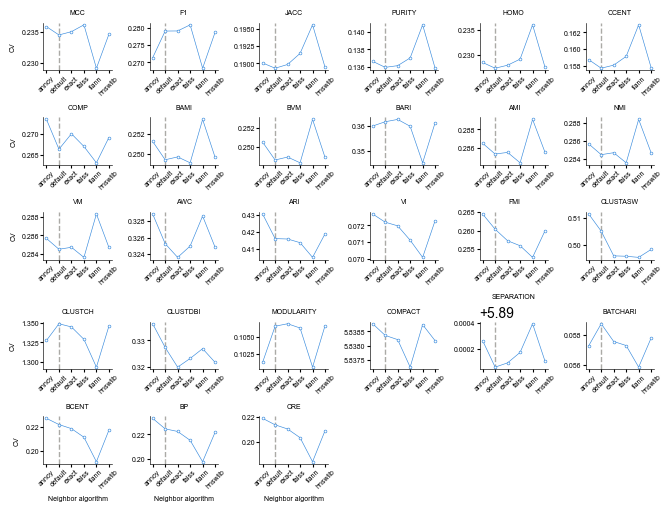

In [41]:
fig = plot_cv_metrics(cvs)
# fig.savefig('../publication_figures/louvain_clustering_neighbor_type_cvs.png', dpi=300, bbox_inches='tight')
fig.show()